<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Procesamiento de Lenguaje Natural · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Análisis Exploratorio del Conjunto de Datos POLAR (SemEval-2026 Task 9)</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Pérez Martínez Ángel Noel, Zamora Antiga Ángel Javier</div><img src="https://raw.githubusercontent.com/makore-0612/vibe-rhythming/refs/heads/main/assets/logoinst.png" width="200"/></div>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Objetivo</span></div>

En este notebook se explora el conjunto de datos multilingüe de [POLAR](https://polar-semeval.github.io/) antes de plantear cualquier modelo. Se revisa el tamaño y la calidad de los datos, el balance de clases, las diferencias entre idiomas, la longitud de los textos y qué tan parecidas son las particiones de entrenamiento y prueba.

POLAR corresponde a la tarea 9 de SemEval-2026 y trata sobre la detección de polarización en textos de redes sociales escritos en 22 idiomas. La tarea se divide en tres subtareas, donde cada una profundiza un poco más en el texto que la anterior.

* **Subtarea 1, detección de polarización.** Es una clasificación binaria en la que se decide si un texto está polarizado o no.
* **Subtarea 2, tipo de polarización.** Es una clasificación multietiqueta que indica hacia qué tipo de grupo se dirige la polarización (político, racial o étnico, religioso, de género o sexual, u otro). Un mismo texto puede tener varios tipos a la vez.
* **Subtarea 3, manifestación de la polarización.** También es multietiqueta y describe cómo se expresa la polarización, por ejemplo con estereotipos, vilificación, deshumanización, lenguaje extremo, falta de empatía o invalidación.

En este proyecto solo trabajaremos las subtareas 1 y 2, por lo que el análisis se centra en sus etiquetas. La subtarea 3 se revisa de forma breve, únicamente para tener una idea general de sus etiquetas y de cómo se relacionan con las otras dos, ya que no se usará en las etapas de modelado.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Preparación de entorno</span></div>

In [1]:
# Manejo de datos
import os
import glob
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibilidad
random_state = 42

# Ruta y grupos de etiquetas por subtarea
ruta_datos = 'data'
tipos = ['political', 'racial/ethnic', 'religious', 'gender/sexual', 'other']
manifestaciones = ['stereotype', 'vilification', 'dehumanization', 'extreme_language', 'lack_of_empathy', 'invalidation']
etiquetas = ['polarization'] + tipos + manifestaciones

Se importan las librerías de manejo de datos y visualización, se fija la semilla `random_state` para que los muestreos sean reproducibles y se definen las listas de etiquetas de cada subtarea. Estas listas se usan a lo largo del notebook para no tener que escribir los nombres de las columnas cada vez.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conjunto de datos</span></div>

In [2]:
def cargar_particion(particion):
    """
    Función que carga y concatena los archivos de todos los idiomas de una partición

    inputs:
    --------
        particion (str): Nombre de la carpeta ('train' o 'test')

    outputs:
    --------
        pandas.DataFrame: Registros de todos los idiomas con una columna adicional 'idioma'
    """
    archivos = sorted(glob.glob(os.path.join(ruta_datos, particion, '*.csv')))
    dfs = [pd.read_csv(f).assign(idioma = os.path.basename(f)[:3]) for f in archivos]
    return pd.concat(dfs, ignore_index = True)

train = cargar_particion('train')
test = cargar_particion('test')

display(train.head())
print(f'\n Tamaño de train: {train.shape}')
print(f' Tamaño de test: {test.shape}')
print(f' Columnas disponibles: {list(train.columns)}')

,id,text,polarization,political,racial/ethnic,religious,gender/sexual,other,stereotype,vilification,dehumanization,extreme_language,lack_of_empathy,invalidation,idioma
0,amh_001aa3e0e9eee80c0064937279edd36a,ኢትዮጵያን ካልዛን: ከሌሎች የበላይ እንጂ እኩል ሆነን መኖር አንችልም የ...,1,1,0,0,0,0,1.0,1.0,0.0,0.0,0.0,0.0,amh
1,amh_001f870fff08e5e2e6d3b7cd70b8526a,ሻደይ በሰቆጣ !! ከነሐሴ 15 /2014 ዓ.ም ጀምሮ ሻደይ በሰቆጣ የማይ...,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,amh
2,amh_003c9e86abf1e64c0e4905949b43fba3,@USER ከእንግዲህ ወዲህ ለዘላለም በሰላም አትኖርም ፣ ነፍስህ ተበታትና...,1,0,0,0,0,1,1.0,0.0,0.0,0.0,0.0,0.0,amh
3,amh_005e7ef6b7e24e534d7007dfc8ce0420,ሲንከባለል የመጣው ዝግተኛው ሶስተኛው የኢትዮጵያ አብዮት! [የህወሓት ፍጻ...,1,1,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0,amh
4,amh_0069ac71c5c5b91179a4590446b6b965,ያሳዝናል !!! ተኝቶ የሚቀለበው የኦሮሚያ ልዩ ሀይል እያለ በወለጋ ሸኔ ...,1,1,1,0,0,0,1.0,1.0,0.0,0.0,0.0,0.0,amh



 Tamaño de train: (73681, 15)
 Tamaño de test: (33288, 16)
 Columnas disponibles: ['id', 'text', 'polarization', 'political', 'racial/ethnic', 'religious', 'gender/sexual', 'other', 'stereotype', 'vilification', 'dehumanization', 'extreme_language', 'lack_of_empathy', 'invalidation', 'idioma']


La función `cargar_particion` lee todos los archivos `.csv` de una carpeta y los junta en un solo `DataFrame`, agregando la columna `idioma` a partir del nombre de cada archivo. Los datos están en `data/`, divididos en `train/` y `test/` con un archivo por idioma, entonces `train` queda con 73,681 registros y `test` con 33,288.

Cada registro es un texto corto con etiquetas binarias de las tres subtareas. La columna `polarization` es la etiqueta de la subtarea 1, las columnas `political`, `racial/ethnic`, `religious`, `gender/sexual` y `other` son las de la subtarea 2, y `stereotype`, `vilification`, `dehumanization`, `extreme_language`, `lack_of_empathy` e `invalidation` son las de la subtarea 3.

Los códigos de idioma siguen el estándar ISO 639-3, y en la siguiente tabla se indica a qué idioma corresponde cada uno.

| Código | Idioma | Código | Idioma | Código | Idioma |
|:--|:--|:--|:--|:--|:--|
| `amh` | Amhárico | `hin` | Hindi | `pol` | Polaco |
| `arb` | Árabe | `ita` | Italiano | `rus` | Ruso |
| `ben` | Bengalí | `khm` | Jemer | `spa` | Español |
| `deu` | Alemán | `mya` | Birmano | `swa` | Suajili |
| `eng` | Inglés | `nep` | Nepalí | `tel` | Telugu |
| `fas` | Persa | `ori` | Oriya | `tur` | Turco |
| `hau` | Hausa | `pan` | Panyabí | `urd` | Urdu |
| | | | | `zho` | Chino |

In [3]:
# Columna exclusiva de test
print(f'Columnas de test que no están en train: {set(test.columns) - set(train.columns)}')
print(f'Valores distintos de canary: {list(test["canary"].unique())}')
test = test.drop(columns = ['canary'])

Columnas de test que no están en train: {'canary'}
Valores distintos de canary: ['c372f4e8-9b5f-11bc-bc24-2ca097b32f1a']


Se revisa qué columnas tiene `test` que no aparecen en `train`. La única es `canary`, que contiene el mismo identificador en todos los registros. Este tipo de cadena se suele incluir en los conjuntos de prueba para detectar si terminaron dentro de los datos de entrenamiento de algún modelo de lenguaje, así que no aporta nada al análisis y se descarta.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Calidad de los datos</span></div>

In [4]:
# Verificación de valores nulos
print('\t Cantidad de registros con valores nulos (train):')
train.isnull().sum()

	 Cantidad de registros con valores nulos (train):


id                      0
text                    0
polarization            0
political               0
racial/ethnic           0
religious               0
gender/sexual           0
other                   0
stereotype          11962
vilification        11962
dehumanization      11962
extreme_language    11962
lack_of_empathy     11962
invalidation        11962
idioma                  0
dtype: int64

Se cuenta cuántos valores nulos tiene cada columna de `train`. Los textos y las etiquetas de las subtareas 1 y 2 están completos, y los únicos nulos aparecen en las seis etiquetas de la subtarea 3, todas con 11,962 registros vacíos. Como el número se repite en las seis columnas, todo indica que hay textos a los que nunca se les anotó la subtarea 3.

In [5]:
# Proporción de registros sin etiquetas de manifestación por idioma
sin_manif = train.groupby('idioma')[manifestaciones].apply(lambda d: d.isnull().all(axis = 1).mean())
print('Idiomas sin etiquetas de la subtarea 3:')
print(sin_manif[sin_manif > 0])

Idiomas sin etiquetas de la subtarea 3:
idioma
ita    1.0
mya    1.0
pol    1.0
rus    1.0
dtype: float64


Para confirmarlo se calcula, por idioma, la proporción de registros que no tienen ninguna etiqueta de manifestación. Los nulos se concentran por completo en italiano, birmano, polaco y ruso, donde ningún texto tiene anotada la subtarea 3. Debido a que el proyecto solo aborda las subtareas 1 y 2, esto no afecta el trabajo posterior, y estos idiomas solo se dejan fuera en la parte de este análisis que revisa las manifestaciones.

In [6]:
# Duplicados y fuga entre particiones
print(f'IDs duplicados en train: {train["id"].duplicated().sum()}')
print(f'Textos duplicados en train: {train["text"].duplicated().sum()}')
print(f'Textos duplicados en test: {test["text"].duplicated().sum()}')
print(f'Textos de test presentes en train: {test["text"].isin(train["text"]).sum()}')

IDs duplicados en train: 0
Textos duplicados en train: 3
Textos duplicados en test: 1
Textos de test presentes en train: 4


Después se buscan registros repetidos. No hay identificadores duplicados, pero sí 3 textos que se repiten dentro de `train` y 1 dentro de `test`. Lo más relevante es que 4 textos de `test` aparecen idénticos en `train`, lo que representa una pequeña fuga entre particiones. Son pocos casos, pero conviene revisarlos de nuevo en el preprocesamiento, puesto que al limpiar los textos podrían aparecer más coincidencias que ahora no se detectan por diferencias de formato.

In [7]:
# Consistencia jerárquica: los tipos y manifestaciones solo deberían aparecer en textos polarizados
no_pol = train[train['polarization'] == 0]
si_pol = train[train['polarization'] == 1]
si_pol_manif = si_pol.dropna(subset = manifestaciones)

print(f'No polarizados con algún tipo: {(no_pol[tipos].sum(axis = 1) > 0).sum()}')
print(f'No polarizados con alguna manifestación: {(no_pol[manifestaciones].sum(axis = 1) > 0).sum()}')
print(f'Polarizados sin ningún tipo: {(si_pol[tipos].sum(axis = 1) == 0).sum()}')
print(f'Polarizados sin ninguna manifestación: {(si_pol_manif[manifestaciones].sum(axis = 1) == 0).sum()}')

No polarizados con algún tipo: 0


No polarizados con alguna manifestación: 0
Polarizados sin ningún tipo: 0
Polarizados sin ninguna manifestación: 0


Las etiquetas siguen una jerarquía, ya que un texto solo puede tener tipo o manifestación si está polarizado. Esta celda separa los textos polarizados (`si_pol`) de los no polarizados (`no_pol`) y verifica que la jerarquía se cumpla en ambos sentidos. Los cuatro conteos dan cero, entonces ningún texto no polarizado tiene un tipo o una manifestación, y todo texto polarizado tiene al menos uno de cada uno.

Los subconjuntos `si_pol` y `no_pol` se reutilizan en las siguientes secciones, al igual que `si_pol_manif`, que contiene solo los textos polarizados con la subtarea 3 anotada.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Distribución por idioma</span></div>

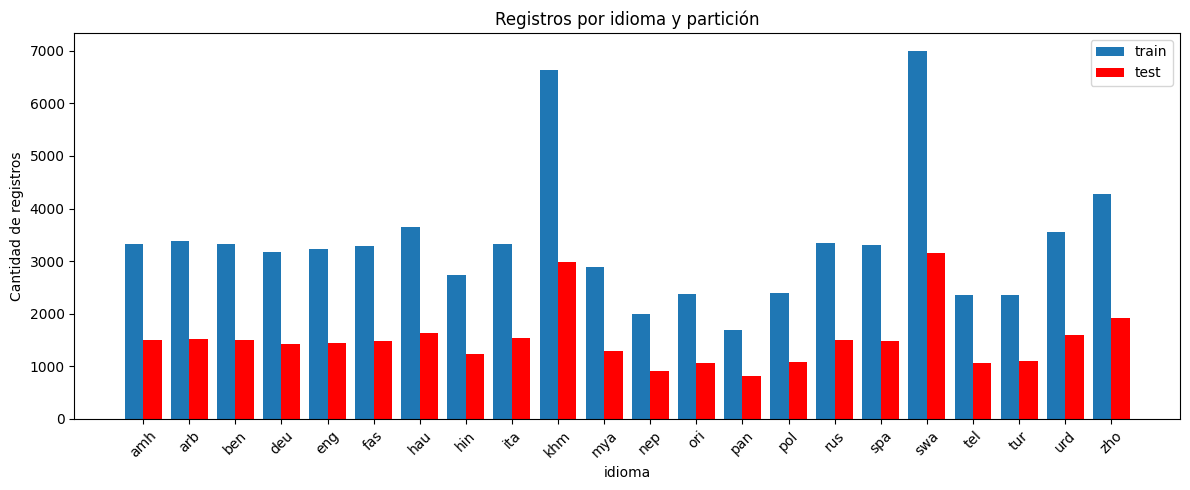

,amh,arb,ben,deu,eng,fas,hau,hin,ita,khm,...,ori,pan,pol,rus,spa,swa,tel,tur,urd,zho
train,3332.0,3380.0,3333.0,3180.0,3222.0,3295.0,3651.0,2744.0,3334.0,6640.0,...,2368.0,1700.0,2391.0,3348.0,3305.0,6991.0,2366.0,2364.0,3563.0,4280.0
test,1501.0,1521.0,1501.0,1432.0,1452.0,1484.0,1644.0,1236.0,1538.0,2988.0,...,1066.0,809.0,1077.0,1508.0,1488.0,3147.0,1066.0,1093.0,1606.0,1927.0
% test,31.1,31.0,31.1,31.0,31.1,31.1,31.0,31.1,31.6,31.0,...,31.0,32.2,31.1,31.1,31.0,31.0,31.1,31.6,31.1,31.0


In [8]:
# Cantidad de registros por idioma y partición
conteo = pd.DataFrame({'train': train['idioma'].value_counts(),
                       'test': test['idioma'].value_counts()}).sort_index()
x = np.arange(len(conteo))

plt.figure(figsize = (12, 5))
plt.bar(x - 0.2, conteo['train'], width = 0.4, label = 'train')
plt.bar(x + 0.2, conteo['test'], width = 0.4, color = 'red', label = 'test')
plt.xticks(x, conteo.index, rotation = 45)
plt.xlabel('idioma')
plt.ylabel('Cantidad de registros')
plt.title('Registros por idioma y partición')
plt.legend()
plt.tight_layout()
plt.show()

conteo['% test'] = round(100 * conteo['test'] / (conteo['train'] + conteo['test']), 1)
display(conteo.rename_axis(None).T)

La gráfica compara cuántos registros tiene cada idioma en `train` y en `test`, y la tabla muestra qué porcentaje de cada idioma se reservó para prueba. Todos los idiomas apartan cerca del 31% de sus textos para `test`, por lo que la división se hizo de forma estratificada por idioma. La mayoría tiene entre 2 mil y 3.7 mil textos de entrenamiento, con excepción del jemer (`khm`) y el suajili (`swa`), que tienen alrededor de 7 mil, el chino (`zho`), con 4.3 mil, y el panyabí (`pan`), que es el más pequeño con 1,700.

Una opción sería trabajar solo con español e inglés, ya que son los únicos idiomas que conocemos, pero eso dejaría fuera la mayor parte del corpus y el modelo perdería capacidad de generalizar. Por esa razón se trabajará con los 22 idiomas. Esto complica el preprocesamiento, debido a que herramientas como la tokenización por palabras o la lematización no funcionan igual en todos ellos, así que en la siguiente etapa se buscarán alternativas que no dependan del idioma.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Subtarea 1. Polarización</span></div>

	 Proporción de textos polarizados (train):
polarization
1    0.531
0    0.469
Name: proportion, dtype: float64


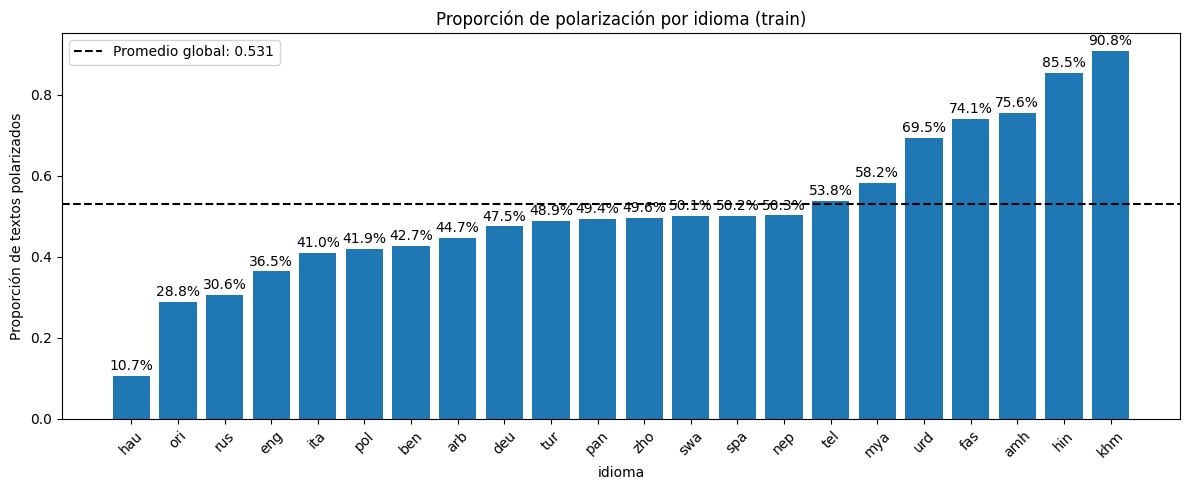

In [9]:
# Balance global de la variable binaria
print('\t Proporción de textos polarizados (train):')
print(train['polarization'].value_counts(normalize = True).round(3))

pol_idioma = train.groupby('idioma')['polarization'].mean().sort_values()

plt.figure(figsize = (12, 5))
barras = plt.bar(pol_idioma.index, pol_idioma.values)
plt.bar_label(barras, fmt = '{:.1%}', padding = 2)
plt.axhline(train['polarization'].mean(), color = 'black', linestyle = '--',
            label = f'Promedio global: {round(train["polarization"].mean(), 3)}')
plt.xticks(rotation = 45)
plt.xlabel('idioma')
plt.ylabel('Proporción de textos polarizados')
plt.title('Proporción de polarización por idioma (train)')
plt.legend()
plt.tight_layout()
plt.show()

Se calcula la proporción de textos polarizados en todo `train` y después en cada idioma. A nivel global las clases están balanceadas, con 53.1% de textos polarizados, pero la gráfica muestra que por idioma la situación cambia bastante. La proporción va desde 10.7% en hausa hasta 90.8% en jemer, y el hindi (85.5%), el amhárico (75.6%) y el persa (74.1%) también están muy cargados hacia la clase positiva.

Esto tiene una consecuencia directa para el modelado, puesto que un modelo multilingüe puede aprender a usar el idioma como atajo y predecir casi siempre la clase mayoritaria de cada uno. Por eso, además de la métrica global, conviene reportar métricas por idioma en la subtarea 1.

In [10]:
# Ejemplos de textos polarizados y no polarizados
pd.set_option('display.max_colwidth', 200)
for idioma in ['eng', 'spa']:
    muestra = train[train['idioma'] == idioma].groupby('polarization').sample(3, random_state = random_state)
    print(f'\n\t Idioma: {idioma}')
    display(muestra[['text', 'polarization'] + tipos])


	 Idioma: eng


,text,polarization,political,racial/ethnic,religious,gender/sexual,other
15550,Valley demonstrators hold ceasefire rally to express,0,0,0,0,0,0
14335,Hamas calls for mobilization to repel PA security forces amid West Bank ops.,0,0,0,0,0,0
13377,TWO INDEPENDENT STATES End Israeli Atrocities End Israeli Apartheid FREE PALESTINE NOW IsraeliWarCrimes,0,0,0,0,0,0
13954,zionist terrorist psychopaths gave military allclear to kill civilians NYT The ZOF reportedly deemed upwards of 20 civilian casualties per airstrike an acceptable death toll.,1,1,1,0,0,0
14666,"BREAKING NEWS ! US FINANCIAL SECTOR UNDERGOING DESHYLOCKATION, IN RESPONSE TO RUSSIAN DENAZIFICATION.",1,1,1,0,0,0
14570,Open borders was always the policy and a tool of RW libertarians and capitalist oligarchs. Thats their irony.,1,1,0,0,0,0



	 Idioma: spa


,text,polarization,political,racial/ethnic,religious,gender/sexual,other
52235,india is parallel universe.,0,0,0,0,0,0
53971,jadejas injury = advantage india,0,0,0,0,0,0
52318,mis favos! la caja negra!!,0,0,0,0,0,0
53623,algunos vamos a perder la compasion que sentimos por el pueblo judio.,1,0,1,1,0,0
53155,lo de los piquitos es de maricon total,1,0,0,0,1,0
52217,barras de pan tenes gordo indigena,1,0,1,0,0,0


Para darnos una idea de cómo se ven los datos, se toman al azar tres textos polarizados y tres no polarizados en inglés y en español. En inglés, dos de los textos no polarizados parecen titulares de noticias, aunque el tercero (*End Israeli Apartheid*) tiene un tono bastante combativo y aun así está marcado como no polarizado, lo que muestra que la frontera entre clases no siempre es evidente. Los polarizados atacan a un grupo de forma directa. En español los textos polarizados contienen insultos o comentarios despectivos hacia judíos, homosexuales o indígenas, y cada uno tiene marcado su tipo en la subtarea 2.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Subtarea 2. Tipo de polarización</span></div>

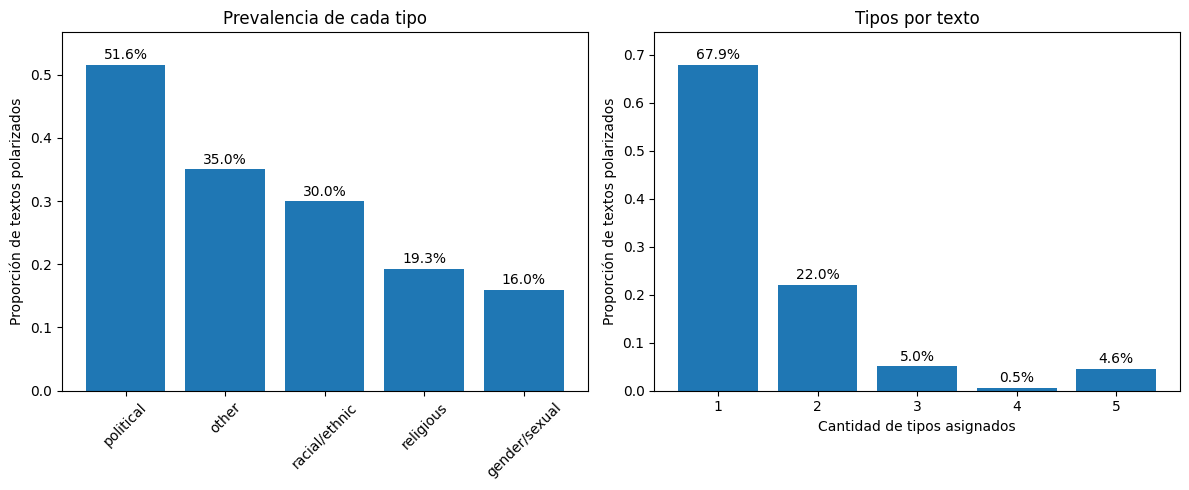

In [11]:
# Prevalencia de cada tipo y cantidad de tipos por texto
prev_tipos = si_pol[tipos].mean().sort_values(ascending = False)
n_tipos = si_pol[tipos].sum(axis = 1).value_counts(normalize = True).sort_index()

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
barras = plt.bar(prev_tipos.index, prev_tipos.values)
plt.bar_label(barras, fmt = '{:.1%}', padding = 2)
plt.xticks(rotation = 45)
plt.ylabel('Proporción de textos polarizados')
plt.title('Prevalencia de cada tipo')
plt.ylim(0, prev_tipos.max() * 1.1)

plt.subplot(1, 2, 2)
barras = plt.bar(n_tipos.index, n_tipos.values)
plt.bar_label(barras, fmt = '{:.1%}', padding = 2)
plt.xlabel('Cantidad de tipos asignados')
plt.ylabel('Proporción de textos polarizados')
plt.title('Tipos por texto')
plt.ylim(0, n_tipos.max() * 1.1)

plt.tight_layout()
plt.show()

Debido a que un texto no polarizado nunca tiene tipo, las proporciones de esta sección se calculan solo sobre los textos polarizados. La gráfica de la izquierda muestra la prevalencia de cada tipo y la de la derecha cuántos tipos tiene cada texto.

El tipo más común es el político (52%), seguido de *other* (35%), el racial o étnico (30%), el religioso (19%) y el de género o sexual (16%). Dos de cada tres textos polarizados tienen un solo tipo y el 22% tiene dos, entonces aunque el problema es multietiqueta, en la mayoría de los casos basta con una etiqueta. Llama la atención que casi el 5% de los textos tenga los cinco tipos a la vez, algo que se explica con el siguiente mapa de calor.

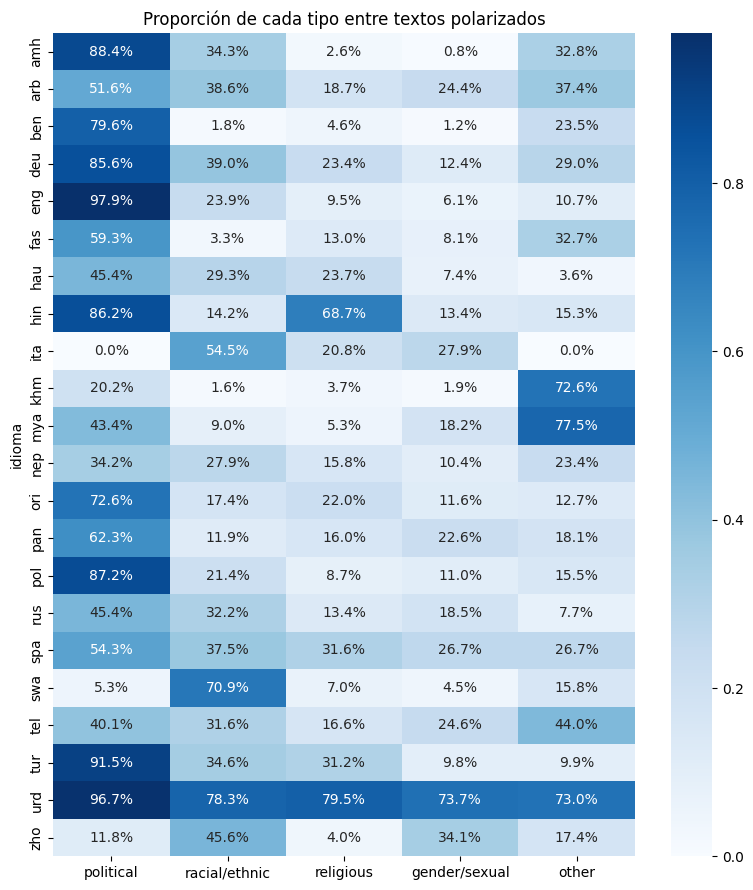

In [12]:
# Prevalencia de cada tipo por idioma
plt.figure(figsize = (8, 9))
sns.heatmap(si_pol.groupby('idioma')[tipos].mean(), annot = True, fmt = '.1%', cmap = 'Blues')
plt.title('Proporción de cada tipo entre textos polarizados')
plt.tight_layout()
plt.show()

El mapa de calor muestra la proporción de cada tipo dentro de los textos polarizados de cada idioma, y deja ver que la distribución cambia mucho de uno a otro. El tipo político domina en la mayoría de los idiomas, con valores cercanos o superiores al 90% en inglés, urdu y turco. Sin embargo, en suajili (5%) e italiano casi no aparece y predomina el racial o étnico, en chino también predomina el racial o étnico, y en jemer y birmano el tipo principal es *other*. En italiano, de hecho, ningún texto de `train` tiene el tipo político ni *other*. El hindi destaca además por el tipo religioso (69%).

El urdu es un caso aparte, ya que todos sus tipos superan el 70%. Esto explica el 5% de textos con cinco tipos de la gráfica anterior y sugiere que en ese idioma se usó un criterio de anotación distinto. Para la subtarea 2 esto significa que un solo modelo para todos los idiomas tendría que aprender distribuciones muy diferentes, lo que favorece la idea de entrenar un modelo por idioma.

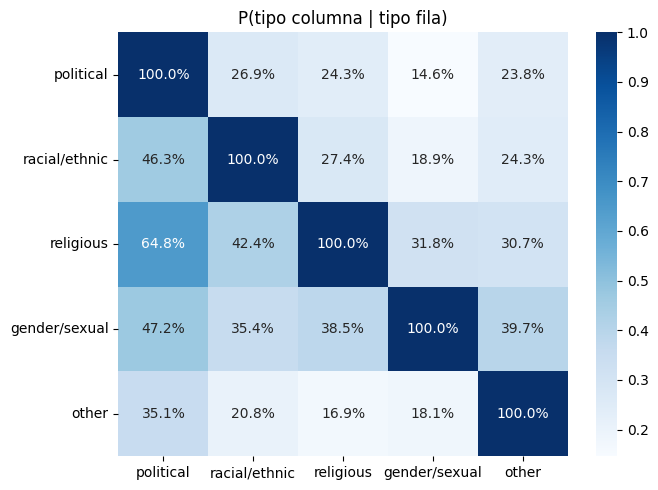

In [13]:
# Coocurrencia condicional: P(columna | fila)
co_tipos = si_pol[tipos].T @ si_pol[tipos]
co_tipos = co_tipos.div(np.diag(co_tipos), axis = 0)

plt.figure(figsize = (7, 5))
sns.heatmap(co_tipos, annot = True, fmt = '.1%', cmap = 'Blues')
plt.title('P(tipo columna | tipo fila)')
plt.tight_layout()
plt.show()

Para ver qué tipos suelen aparecer juntos se calcula la coocurrencia condicional, donde cada celda indica la probabilidad de que un texto tenga el tipo de la columna dado que tiene el tipo de la fila. La matriz no es simétrica, puesto que los tipos tienen prevalencias distintas. Por ejemplo, el 65% de los textos religiosos también son políticos, pero solo el 24% de los políticos son religiosos.

En general, los tipos menos frecuentes (religioso y de género o sexual) aparecen acompañados de otros con más frecuencia que el político, que suele aparecer solo. Parte de esta coocurrencia viene del urdu, donde casi todos los tipos aparecen juntos. Esta relación entre etiquetas es la que intenta aprovechar una cadena de clasificadores, que se prueba en el modelado de la subtarea 2.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Subtarea 3. Manifestación de la polarización (complementario)</span></div>

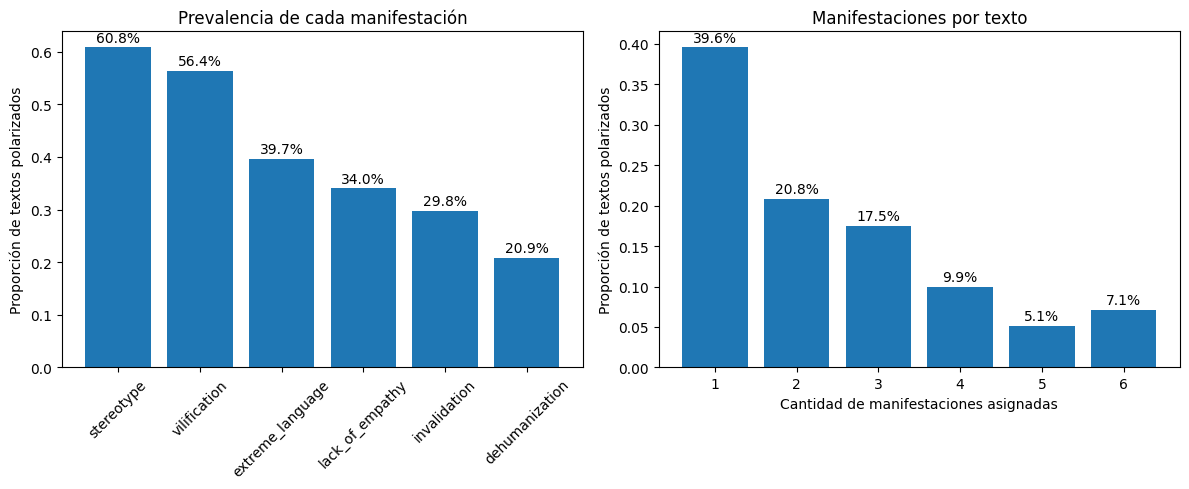

In [14]:
# Prevalencia de cada manifestación y cantidad de manifestaciones por texto
prev_manif = si_pol_manif[manifestaciones].mean().sort_values(ascending = False)
n_manif = si_pol_manif[manifestaciones].sum(axis = 1).value_counts(normalize = True).sort_index()

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
barras = plt.bar(prev_manif.index, prev_manif.values)
plt.bar_label(barras, fmt = '{:.1%}', padding = 2)
plt.xticks(rotation = 45)
plt.ylabel('Proporción de textos polarizados')
plt.title('Prevalencia de cada manifestación')

plt.subplot(1, 2, 2)
barras = plt.bar(n_manif.index, n_manif.values)
plt.bar_label(barras, fmt = '{:.1%}', padding = 2)
plt.xlabel('Cantidad de manifestaciones asignadas')
plt.ylabel('Proporción de textos polarizados')
plt.title('Manifestaciones por texto')

plt.tight_layout()
plt.show()

Esta sección es solo complementaria, ya que la subtarea 3 no forma parte del proyecto. Se consideran únicamente los textos polarizados de los idiomas que tienen la subtarea anotada. Las manifestaciones más frecuentes son el estereotipo (61%) y la vilificación (56%), y la menos común es la deshumanización (21%). A diferencia de los tipos, aquí lo normal es que un texto tenga varias manifestaciones, puesto que solo el 40% tiene una sola.

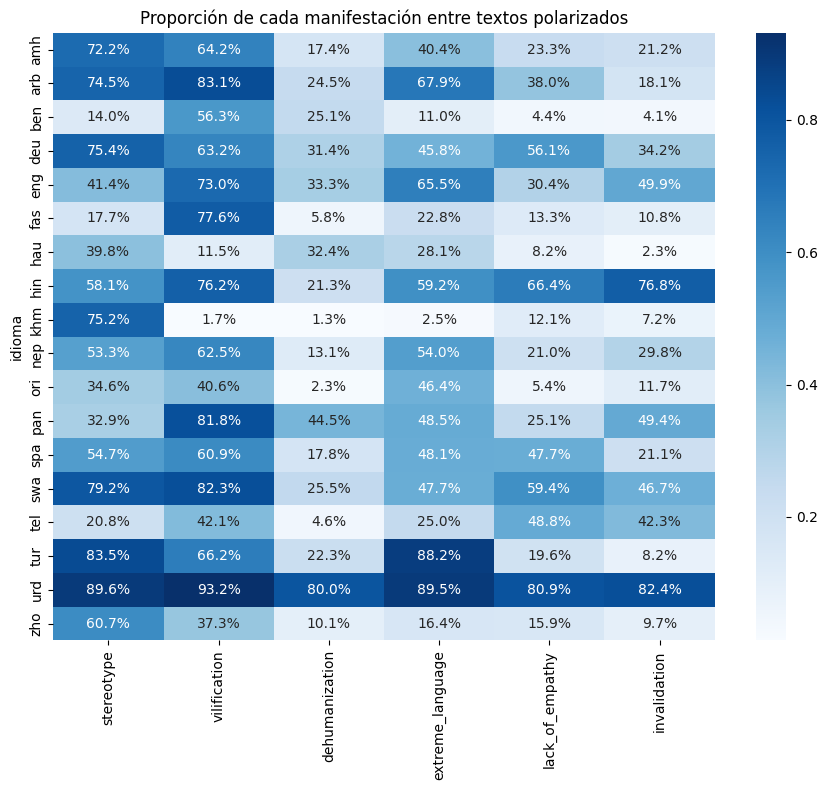

In [15]:
# Prevalencia de cada manifestación por idioma
plt.figure(figsize = (9, 8))
sns.heatmap(si_pol_manif.groupby('idioma')[manifestaciones].mean(), annot = True, fmt = '.1%', cmap = 'Blues')
plt.title('Proporción de cada manifestación entre textos polarizados')
plt.tight_layout()
plt.show()

El mapa de calor muestra la prevalencia de cada manifestación en cada idioma. Al igual que con los tipos, la distribución cambia bastante entre idiomas. El urdu vuelve a tener todas las etiquetas por encima del 80%, mientras que en jemer casi todo es estereotipo (75%) y las demás manifestaciones apenas aparecen.

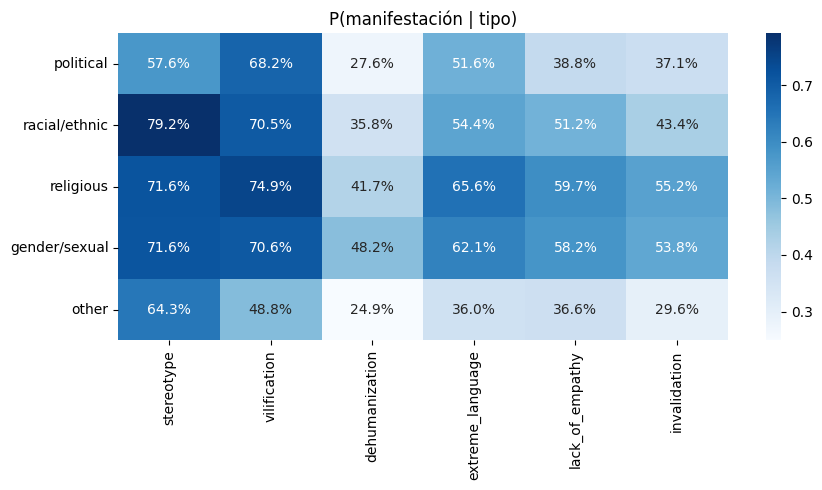

In [16]:
# Relación entre tipo y manifestación: P(manifestación | tipo)
tipo_manif = pd.DataFrame({t: si_pol_manif.loc[si_pol_manif[t] == 1, manifestaciones].mean() for t in tipos}).T

plt.figure(figsize = (9, 5))
sns.heatmap(tipo_manif, annot = True, fmt = '.1%', cmap = 'Blues')
plt.title('P(manifestación | tipo)')
plt.tight_layout()
plt.show()

Por último se calcula la proporción de cada manifestación según el tipo de polarización. El estereotipo y la vilificación son las más comunes en todos los tipos, y los textos religiosos y de género o sexual son los que acumulan más manifestaciones. La deshumanización, por ejemplo, llega al 42% y al 48% en esos dos tipos, contra 28% en los políticos. No se profundiza más en estos resultados, debido a que la subtarea 3 queda fuera del alcance del proyecto.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Longitud de los textos</span></div>

count    73681.0
mean       106.8
std         75.1
min          2.0
25%         54.0
50%         89.0
75%        131.0
max       2680.0
Name: n_caracteres, dtype: float64

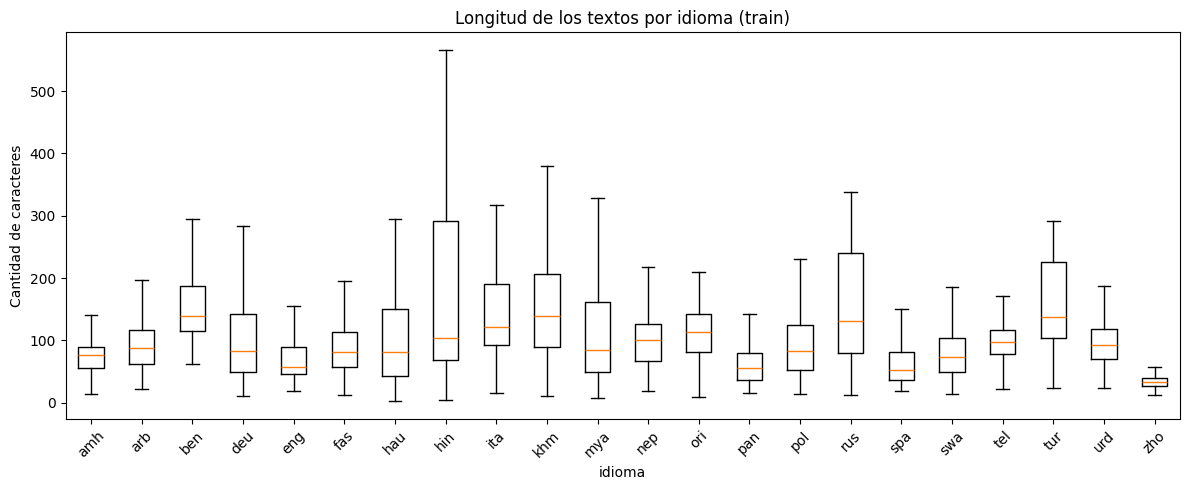

In [17]:
train['n_caracteres'] = train['text'].str.len()
display(train['n_caracteres'].describe().round(1))

idiomas = sorted(train['idioma'].unique())

plt.figure(figsize = (12, 5))
plt.boxplot([train.loc[train['idioma'] == i, 'n_caracteres'] for i in idiomas],
            tick_labels = idiomas, showfliers = False)
plt.xticks(rotation = 45)
plt.xlabel('idioma')
plt.ylabel('Cantidad de caracteres')
plt.title('Longitud de los textos por idioma (train)')
plt.tight_layout()
plt.show()

La longitud se mide en caracteres y no en palabras, ya que el chino, el jemer y el birmano no separan sus palabras con espacios y contar palabras con `split()` subestimaría mucho su longitud. En el diagrama de caja se omiten los valores atípicos para que la escala sea legible.

Los textos son cortos, con una mediana de 89 caracteres, aunque hay algunos de más de 2,600. Por idioma la mediana va de 33 caracteres en chino, donde cada carácter equivale a una palabra o a una sílaba, hasta cerca de 140 en bengalí, jemer y turco.

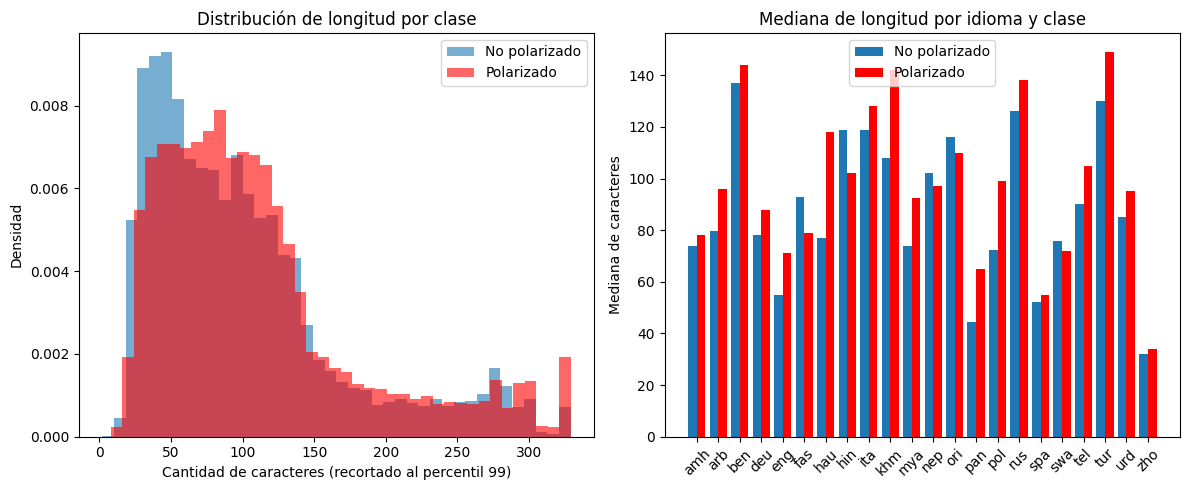

In [18]:
# Longitud según polarización
limite = train['n_caracteres'].quantile(0.99)
mediana = train.groupby(['idioma', 'polarization'])['n_caracteres'].median().unstack()
x = np.arange(len(mediana))

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.hist(no_pol['text'].str.len().clip(upper = limite), bins = 40, alpha = 0.6, density = True, label = 'No polarizado')
plt.hist(si_pol['text'].str.len().clip(upper = limite), bins = 40, alpha = 0.6, density = True, color = 'red', label = 'Polarizado')
plt.xlabel('Cantidad de caracteres (recortado al percentil 99)')
plt.ylabel('Densidad')
plt.title('Distribución de longitud por clase')
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(x - 0.2, mediana[0], width = 0.4, label = 'No polarizado')
plt.bar(x + 0.2, mediana[1], width = 0.4, color = 'red', label = 'Polarizado')
plt.xticks(x, mediana.index, rotation = 45)
plt.ylabel('Mediana de caracteres')
plt.title('Mediana de longitud por idioma y clase')
plt.legend()

plt.tight_layout()
plt.show()

Para saber si la longitud ayuda a distinguir las clases se compara la distribución de los textos polarizados y no polarizados, recortada al percentil 99 para que la cola larga no aplaste la gráfica, y la mediana por idioma y clase. Los textos polarizados son apenas más largos, con una mediana de 94 caracteres contra 84, y las dos distribuciones se traslapan casi por completo. Por idioma la diferencia incluso cambia de signo, ya que en hausa y jemer los polarizados son bastante más largos, pero en hindi y persa son más cortos. Entonces la longitud por sí sola no sirve para separar las clases.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Comparación entre entrenamiento y prueba</span></div>

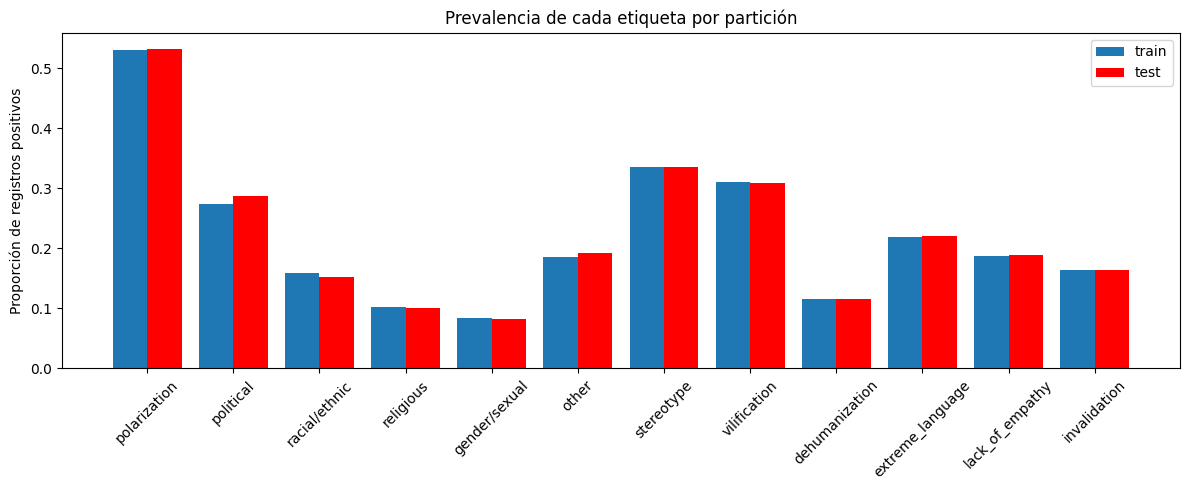

Diferencia absoluta máxima: 0.0137 (political)


In [19]:
# Prevalencia de cada etiqueta en ambas particiones
comparacion = pd.DataFrame({'train': train[etiquetas].mean(), 'test': test[etiquetas].mean()})
x = np.arange(len(comparacion))

plt.figure(figsize = (12, 5))
plt.bar(x - 0.2, comparacion['train'], width = 0.4, label = 'train')
plt.bar(x + 0.2, comparacion['test'], width = 0.4, color = 'red', label = 'test')
plt.xticks(x, comparacion.index, rotation = 45)
plt.ylabel('Proporción de registros positivos')
plt.title('Prevalencia de cada etiqueta por partición')
plt.legend()
plt.tight_layout()
plt.show()

diferencia = (comparacion['train'] - comparacion['test']).abs()
print(f'Diferencia absoluta máxima: {round(diferencia.max(), 4)} ({diferencia.idxmax()})')

Se compara la prevalencia de cada etiqueta en `train` y en `test` para verificar que ambas particiones vienen de la misma distribución. Las barras son casi iguales y la diferencia máxima es de 1.4 puntos porcentuales, en *political*. Por lo tanto, un modelo que se valide con una parte de `train` debería comportarse de forma parecida al evaluarse en `test`.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

In [20]:
# Tabla resumen por idioma
resumen = pd.DataFrame({
    'n_train': train.groupby('idioma').size(),
    'n_test': test.groupby('idioma').size(),
    '% polarizado': (100 * train.groupby('idioma')['polarization'].mean()).round(1),
    'subtarea 3': train.groupby('idioma')['stereotype'].apply(lambda s: s.notnull().any()),
    'mediana caracteres': train.groupby('idioma')['n_caracteres'].median()
})
display(resumen)

,n_train,n_test,% polarizado,subtarea 3,mediana caracteres
idioma,,,,,
amh,3332,1501,75.6,True,77.0
arb,3380,1521,44.7,True,88.5
ben,3333,1501,42.7,True,139.0
deu,3180,1432,47.5,True,83.0
eng,3222,1452,36.5,True,58.0
fas,3295,1484,74.1,True,81.0
hau,3651,1644,10.7,True,82.0
hin,2744,1236,85.5,True,103.0
ita,3334,1538,41.0,False,121.0


La tabla resume, para cada idioma, el número de textos en cada partición, el porcentaje de textos polarizados, si tiene anotada la subtarea 3 y la mediana de caracteres.

Hay 73,681 textos de entrenamiento y 33,288 de prueba en 22 idiomas, y todos los idiomas reservan cerca del 31% de sus textos para prueba. La mayoría tiene entre 2 mil y 3.7 mil textos de entrenamiento, con excepción del jemer y el suajili, que tienen unos 7 mil, el chino, con 4.3 mil, y el panyabí, con 1,700.

Los datos no tienen valores faltantes en los textos ni en las etiquetas de las subtareas 1 y 2, y las etiquetas respetan la jerarquía, puesto que ningún texto no polarizado tiene tipo y todo texto polarizado tiene al menos uno. Los únicos nulos están en la subtarea 3, que no se anotó en italiano, birmano, polaco ni ruso, pero esto no afecta al proyecto porque solo se trabajarán las subtareas 1 y 2.

Solo 3 textos se repiten dentro de `train` y 4 textos de `test` aparecen idénticos en `train`. En el preprocesamiento se repetirá esta revisión sobre el texto limpio, por si aparecen más coincidencias.

En la subtarea 1 las clases están balanceadas a nivel global (53.1% polarizado), pero por idioma la proporción va del 10.7% en hausa al 90.8% en jemer. Un modelo multilingüe podría usar el idioma como atajo, por lo que conviene reportar métricas por idioma además de la global.

En la subtarea 2 el tipo más común es el político (52% de los textos polarizados), seguido de *other* (35%), el racial o étnico (30%), el religioso (19%) y el de género o sexual (16%). Dos de cada tres textos tienen un solo tipo, aunque la distribución cambia mucho entre idiomas. El político domina en la mayoría, pero en suajili e italiano predomina el racial o étnico y en jemer y birmano predomina *other*. Hay dos casos que habrá que tener en cuenta al modelar. En italiano ningún texto de `train` tiene el tipo político ni *other*, y en urdu el 71% de los textos polarizados tiene los cinco tipos a la vez, lo que apunta a un criterio de anotación distinto. Estas diferencias hacen pensar que entrenar un modelo por idioma puede funcionar mejor que un solo modelo global.

De la subtarea 3 solo se tomó nota de que, a diferencia de los tipos, lo habitual es que un texto tenga varias manifestaciones, y de que el estereotipo y la vilificación son las más frecuentes.

Los textos son cortos (mediana de 89 caracteres) y los polarizados son apenas más largos que los no polarizados (94 contra 84), así que la longitud no distingue las clases. Finalmente, la prevalencia de cada etiqueta es casi igual en ambas particiones, con una diferencia máxima de 1.4 puntos, entonces la validación dentro de `train` debería dar una buena idea del desempeño en `test`.